# Combining axes: zero-shot loss across depth, expert, and head pruning together

Part of plan.md step 2.4 -- the first real multi-axis pruning experiment.
`05_depth_pruning_sweep.ipynb`, `06_expert_pruning_sweep.ipynb`, and
`07_head_pruning_sweep.ipynb` each pruned one axis at a time; this notebook
actually combines them into single candidates and measures the resulting
zero-shot loss on `Qwen3-30B-A3B-Base`, the same way as the single-axis
sweeps (`bonsai.importance.depth.mean_loss`, 32 fresh calibration samples,
seed 1).

**Target counts per axis, three aggressiveness tiers** -- chosen so each
axis's own single-axis zero-shot cost lands in a similar band, not a
uniform pruned-fraction across axes (experts are dramatically more
redundant than depth or heads, established in the single-axis sweeps, so a
uniform fraction would leave experts badly under-exploited):

| tier | depth (of 48) | experts (of 128/layer) | heads (of 8/group) |
|---|---|---|---|
| conservative | n=8 (+12.0%) | n=48 (+13.7%) | k=1 (+5.2%) |
| moderate | n=12 (+21.9%) | n=64 (+25.5%) | k=2 (+21.4%) |
| aggressive | n=16 (+41.6%) | n=80 (+46.3%) | k=3 (+58.5%) |

**Four combination types per tier**: depth+experts, depth+heads,
experts+heads, and all three -- 12 candidates total, plus a fresh baseline
run on the same instance for direct comparison.

**Real correctness detail** (see `scratch_combined_pruning_sweep.py`,
deleted after this run, same convention as the single-axis sweeps'
orchestration scripts): `expert_scores`/`head_scores`/`depth_scores` are
indexed by the *original* 48-layer model's layer index. When a candidate
combines depth pruning with experts and/or heads, depth pruning runs
first (removing layers, renumbering survivors), so the expert/head
selection has to be computed against only the surviving layers' scores, in
their new post-depth-pruning order -- including remapping the Super
Experts `protected` dict to whichever of layers 1/2/3 actually survive.

In [1]:
import json

import torch

RUN_DIR = "../runs/20260920T173342Z-7aa2204-combined-pruning-sweep"
data = torch.load(f"{RUN_DIR}/combined-pruning-sweep.pt", weights_only=False)

results = data["results"]
tiers = list(data["tiers"].keys())
combos = data["combos"]
baseline_loss = next(r["loss"] for r in results if r["combo"] == "baseline")

print(
    f"{data['num_layers']} layers, {data['num_samples']} calibration samples, mean length {data['mean_length']:.0f} tokens"
)
print(f"tiers: {json.dumps(data['tiers'], indent=2)}")
print(f"baseline (nothing pruned) loss: {baseline_loss:.4f}")
print(f"{len(results)} total candidates evaluated")

48 layers, 32 calibration samples, mean length 176 tokens
tiers: {
  "conservative": {
    "depth_n": 8,
    "expert_n": 48,
    "head_k": 1
  },
  "moderate": {
    "depth_n": 12,
    "expert_n": 64,
    "head_k": 2
  },
  "aggressive": {
    "depth_n": 16,
    "expert_n": 80,
    "head_k": 3
  }
}
baseline (nothing pruned) loss: 0.9668
13 total candidates evaluated


## The main result

One group of bars per tier, one bar per combination type. Log-scale
$y$-axis since loss spans nearly 4x across tiers.

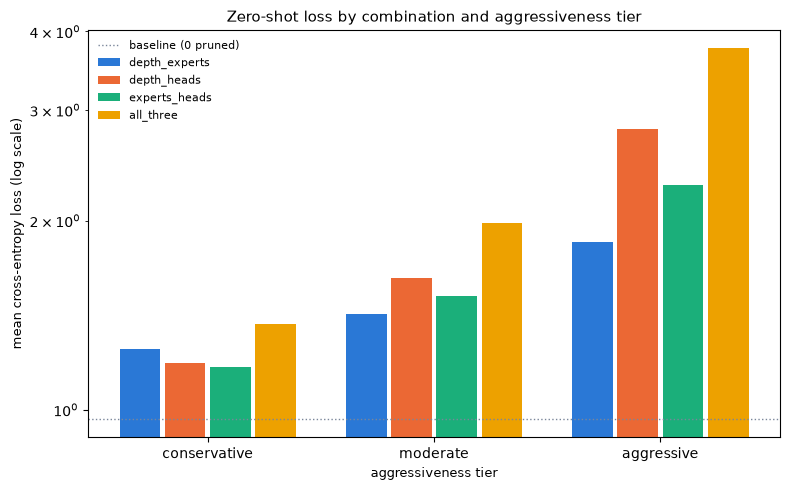

In [2]:
from bonsai.pruning.viz import plot_combined_pruning_sweep

combo_losses = {
    combo: [
        next(r["loss"] for r in results if r["tier"] == tier and r["combo"] == combo)
        for tier in tiers
    ]
    for combo in combos
}

fig = plot_combined_pruning_sweep(tiers, combo_losses, baseline_loss=baseline_loss)
fig.savefig(f"{RUN_DIR}/combined_pruning_sweep.png", dpi=150)
fig.savefig(f"{RUN_DIR}/combined_pruning_sweep.pdf")

## Numbers behind the plot

In [3]:
header = f"{'tier':<13} {'combo':<14} {'loss':>8} {'vs baseline':>12}"
print(header)
print("-" * len(header))
for tier in tiers:
    for combo in combos:
        loss = next(r["loss"] for r in results if r["tier"] == tier and r["combo"] == combo)
        rel = loss / baseline_loss - 1
        print(f"{tier:<13} {combo:<14} {loss:>8.4f} {rel:>+11.1%}")

tier          combo              loss  vs baseline
--------------------------------------------------
conservative  depth_experts    1.2513      +29.4%
conservative  depth_heads      1.1884      +22.9%
conservative  experts_heads    1.1681      +20.8%
conservative  all_three        1.3693      +41.6%
moderate      depth_experts    1.4201      +46.9%
moderate      depth_heads      1.6221      +67.8%
moderate      experts_heads    1.5180      +57.0%
moderate      all_three        1.9842     +105.2%
aggressive    depth_experts    1.8480      +91.1%
aggressive    depth_heads      2.7972     +189.3%
aggressive    experts_heads    2.2744     +135.2%
aggressive    all_three        3.7584     +288.7%


## Do axes compound independently, or interact?

The single-axis sweeps already give each axis's own zero-shot cost at
these counts. If axes contributed independent, uncorrelated damage, a
combined candidate's relative loss increase should be close to the *naive
multiplicative* prediction: $(1+a)(1+b)\cdots - 1$, where $a, b, \ldots$
are each axis's own single-axis relative loss increase. Comparing that
prediction to what we actually measured tells us whether the axes are
genuinely independent or interact.

In [4]:
# Single-axis costs at the exact same counts, from 05/06/07's own sweeps.
single_axis_cost = {
    "conservative": {"depth": 0.120, "experts": 0.137, "heads": 0.052},
    "moderate": {"depth": 0.219, "experts": 0.255, "heads": 0.214},
    "aggressive": {"depth": 0.416, "experts": 0.463, "heads": 0.585},
}
combo_axes = {
    "depth_experts": ["depth", "experts"],
    "depth_heads": ["depth", "heads"],
    "experts_heads": ["experts", "heads"],
    "all_three": ["depth", "experts", "heads"],
}

header = f"{'tier':<13} {'combo':<14} {'actual':>9} {'naive mult.':>12} {'excess':>9}"
print(header)
print("-" * len(header))
for tier in tiers:
    for combo in combos:
        actual = (
            next(r["loss"] for r in results if r["tier"] == tier and r["combo"] == combo)
            / baseline_loss
            - 1
        )
        naive = 1.0
        for axis in combo_axes[combo]:
            naive *= 1 + single_axis_cost[tier][axis]
        naive -= 1
        print(f"{tier:<13} {combo:<14} {actual:>+8.1%} {naive:>+11.1%} {actual - naive:>+8.1%}")

tier          combo             actual  naive mult.    excess
-------------------------------------------------------------
conservative  depth_experts    +29.4%      +27.3%    +2.1%
conservative  depth_heads      +22.9%      +17.8%    +5.1%
conservative  experts_heads    +20.8%      +19.6%    +1.2%
conservative  all_three        +41.6%      +34.0%    +7.7%
moderate      depth_experts    +46.9%      +53.0%    -6.1%
moderate      depth_heads      +67.8%      +48.0%   +19.8%
moderate      experts_heads    +57.0%      +52.4%    +4.7%
moderate      all_three       +105.2%      +85.7%   +19.5%
aggressive    depth_experts    +91.1%     +107.2%   -16.0%
aggressive    depth_heads     +189.3%     +124.4%   +64.9%
aggressive    experts_heads   +135.2%     +131.9%    +3.4%
aggressive    all_three       +288.7%     +228.3%   +60.4%


**depth+heads interacts genuinely badly** -- worse than independent
compounding at every tier, and the excess grows sharply with
aggressiveness (+5.1pp conservative, +19.8pp moderate, +64.9pp
aggressive). **depth+experts is actually *subadditive*** at the moderate
and aggressive tiers (-6.1pp, -16.0pp) -- cheaper than independent
compounding predicts. experts+heads sits close to the naive prediction
throughout (+1.2pp to +4.7pp).

A plausible reading, not a proven one: depth pruning removes whole
layers, including their attention heads entirely. Combining it with
separate head pruning on the *surviving* layers may be compounding damage
to the same mechanism (attention) rather than spreading the cut across
more independent components -- unlike depth+experts, which removes layers
(attention + routing) alongside MLP/expert capacity on the survivors,
hitting more orthogonal parts of the model. Consistent with this: experts
are also the single most redundant axis by a wide margin (07's own
cross-axis comparison), so depth+experts is the cheapest pairwise combo at
every tier except conservative, while depth+heads is the most expensive
pairwise combo at every tier.

## Summary

- **all\_three is the worst zero-shot candidate at every tier**, as
  expected from combining the most axes -- but per 2407.14679's own
  finding (depth/width rankings can flip after retraining), this is not
  grounds to drop it before a real lightweight retrain (plan.md 4.1)
  actually tests that.
- **depth+experts is consistently the cheapest or near-cheapest pairwise
  combination**, and the only one that compounds *better* than
  independence would predict at the two more aggressive tiers.
- **depth+heads is consistently the most expensive pairwise combination**,
  and the interaction between the two gets markedly worse than
  independent compounding as more is pruned from each.
- **experts+heads tracks the naive independent-compounding prediction
  closely** at every tier -- the closest thing to "the axes really are
  independent" among the three pairwise combinations tested.

**What this means going forward:** these are zero-shot numbers only --
the actual candidate-selection goal (a TypeScript-specialized model that's
smaller, faster, and cheaper to serve than the unpruned baseline, and
high-accuracy on TypeScript specifically) needs real retraining and real
eval-suite numbers (plan.md 4.1/4.2), not zero-shot loss alone. This sweep
narrows the candidate space and surfaces a real interaction effect worth
reporting either way, not a final ranking.